## Partie 1 : Définition du problème

### Contexte

Le domaine de l’assurance santé cherche à estimer les coûts médicaux des assurés afin de mieux gérer les risques et proposer des tarifs adaptés.  
Le jeu de données présenté contient plusieurs informations personnelles et médicales des clients, ainsi que le montant des frais médicaux facturés (`charges`).

L’objectif principal est d’analyser les facteurs qui influencent les coûts d’assurance santé et de construire un modèle capable de prédire ces coûts.
- **Variables numériques :** `age`, `bmi`, `children`, `charges`
- **Variables catégorielles :** `sex`, `smoker`, `region`
---
### Structure du dataset

- **1383 lignes 
- **7 colonnes (variables explicatives + variable cible)**
- **Variable cible :** `charges`  
  (montant des frais médicaux facturés à l’assuré)

---


### Objectif de l’étude

L’objectif de cette étude est :

- Comprendre la relation entre les caractéristiques des assurés et les frais médicaux.
- Identifier les variables ayant le plus d’impact sur les coûts d’assurance.
- Réaliser une analyse exploratoire des données (EDA).
- Préparer les données pour le machine learning.
- Construire un modèle de prédiction des charges médicales.

---

### But du projet

Ce projet vise à développer un système prédictif permettant :

- d’estimer les dépenses médicales futures ;
- d’aider les compagnies d’assurance à ajuster leurs politiques tarifaires ;
- d’identifier les profils à risque élevé ;
- d’améliorer la prise de décision basée sur les données.

---

### Description des variables
Le dataset contient les variables suivantes :

| Variable | Description | Type |
|---|---|---|
| `age` | Âge de l’assuré | Numérique |
| `sex` | Sexe de l’assuré (`male` / `female`) | Catégorielle |
| `bmi` | Body Mass Index (Indice de masse corporelle) | Numérique |
| `children` | Nombre d’enfants à charge | Numérique |
| `smoker` | Indique si la personne fume (`yes` / `no`) | Catégorielle |
| `region` | Région géographique de résidence | Catégorielle |
| `charges` | Frais médicaux facturés par l’assurance | Numérique (variable cible) |

---

### Nature du problème

Ce projet est un problème de :

- **Machine Learning supervisé**
- **Régression**

car la variable cible `charges` est une valeur numérique continue.



In [1]:
import numpy as np
import pandas as pd

## Partie 2 : Data Collection & Exploration

In [2]:
df=pd.read_csv('insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
df.shape

(1338, 7)

In [5]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [6]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [10]:
df = df.drop_duplicates()

df.duplicated().sum()

np.int64(0)

## Partie 3 : Data Cleaning

In [11]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR =Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(col, ((df[col] < lower) | (df[col] > upper)).sum())

age 0
bmi 9
children 0
charges 139


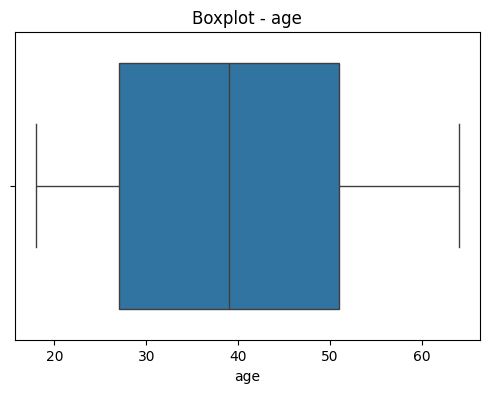

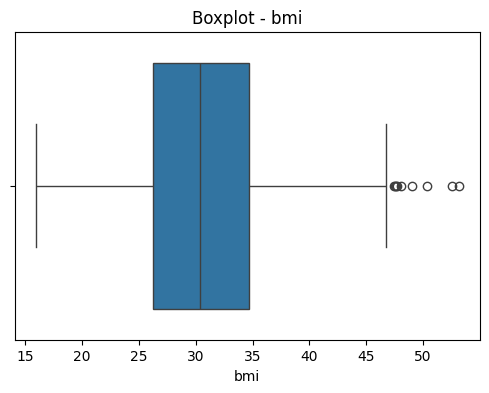

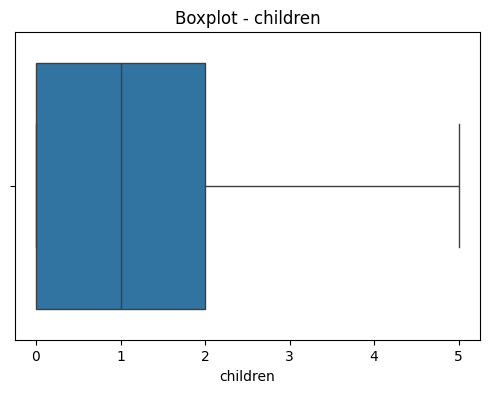

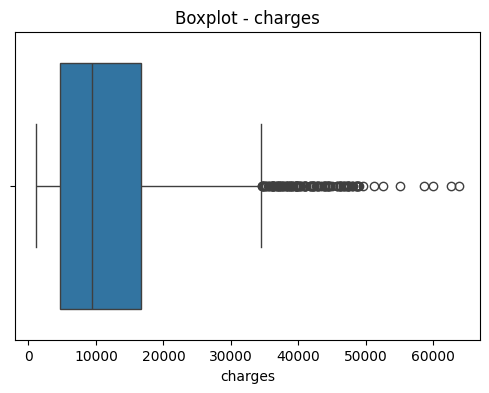

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
 
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot - {col}')

### Conclusion des valeurs aberrantes:
#### *BMI:*
##### • les points à droite (BMI > 47) représentent probablement des personnes en situation d’obésité sévère ou extrême, Dans un contexte médical ces valeurs peuvent exister réellement
#### *charges:*
##### •Le boxplot montre clairement plusieurs outliers dans charges (les points à droite après la moustache).
##### → Mais dans ce dataset, c’est généralement normal et attendu, ce ne sont pas forcément des erreurs; il ne faut pas les supprimer automatiquement 

## Partie 4 : Analyse Exploratoire Des Donnees (EDA)
### A. Analyse des variables numériques

Nous analysons:

    • distribution de age    
    • distribution de bmi 
    • age vs charges
    • bmi vs charges
    

In [13]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


### 1. Distribution des charges

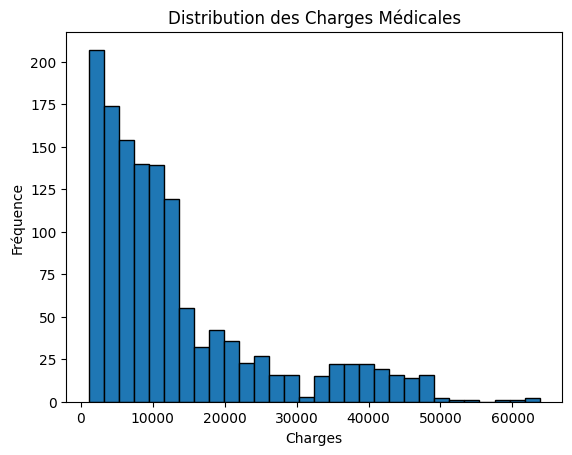

In [14]:
plt.figure()
plt.hist(df["charges"], bins=30, edgecolor="black")
plt.xlabel("Charges")
plt.ylabel("Fréquence")
plt.title("Distribution des Charges Médicales")
plt.show()

### 2. distribution des ages et bmi:

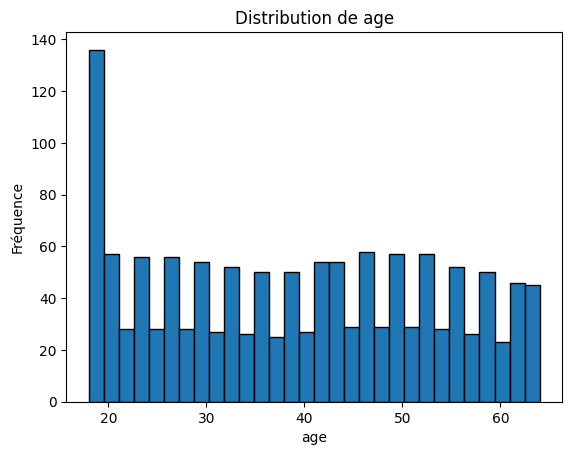

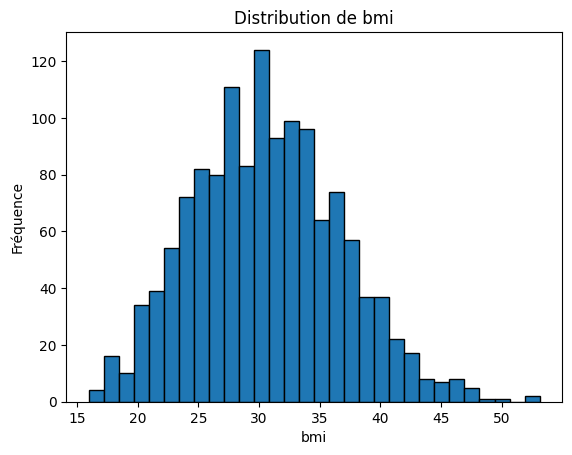

In [15]:
col_re = num_cols.drop(['children','charges'])

for col in col_re:
    plt.figure()
    plt.hist(df[col], bins=30, edgecolor="black")
    plt.xlabel(col)
    plt.ylabel("Fréquence")
    plt.title(f"Distribution de {col}")
plt.show()

### 3. L’âge influence-t-il les frais médicaux ?

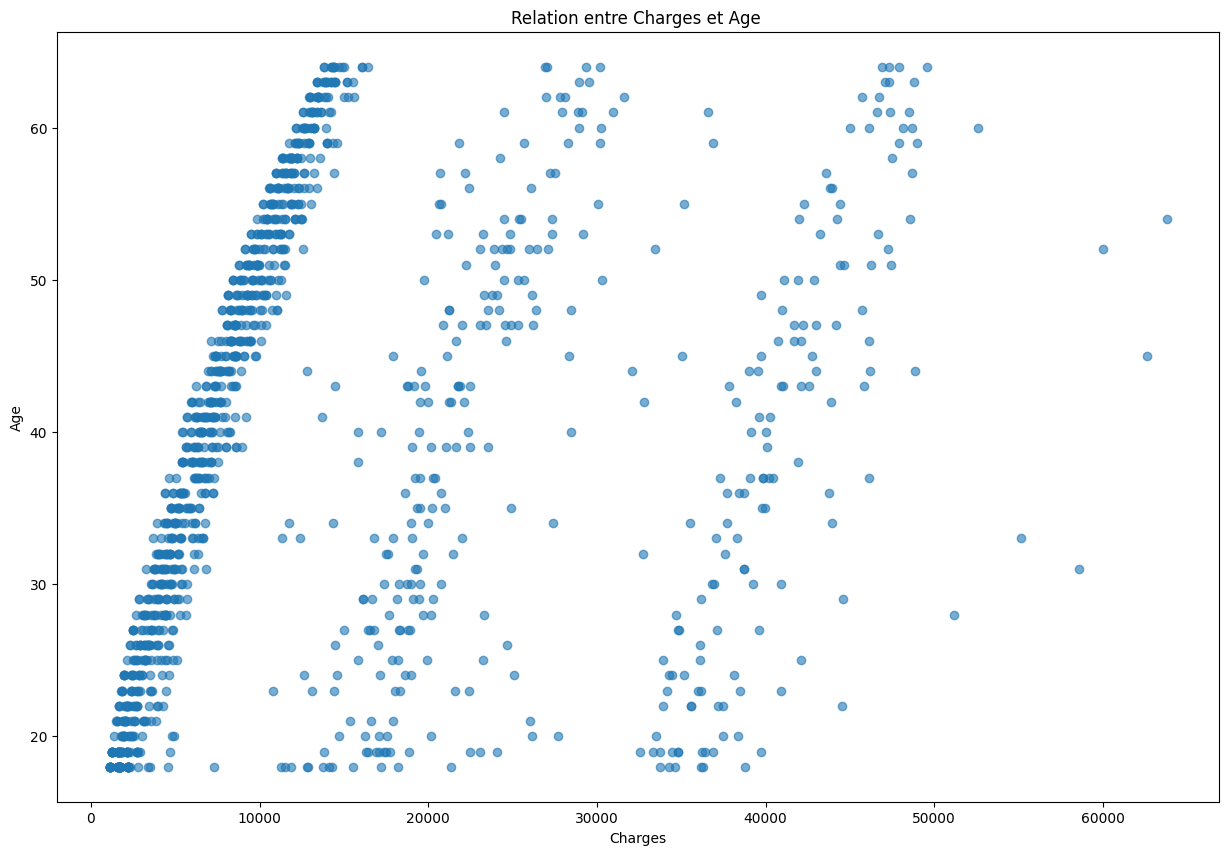

In [16]:
plt.figure(figsize=(15,10))
plt.scatter(df["charges"], df["age"], alpha=0.6)
plt.xlabel("Charges")
plt.ylabel("Age")
plt.title("Relation entre Charges et Age ")
plt.show()

les personnes âgées ont souvent des charges plus élevées
mais forte dispersion → autres facteurs importants

### 4. Le BMI est-il un facteur clé des coûts ?
Les personnes avec un BMI élevé paient-elles plus ?

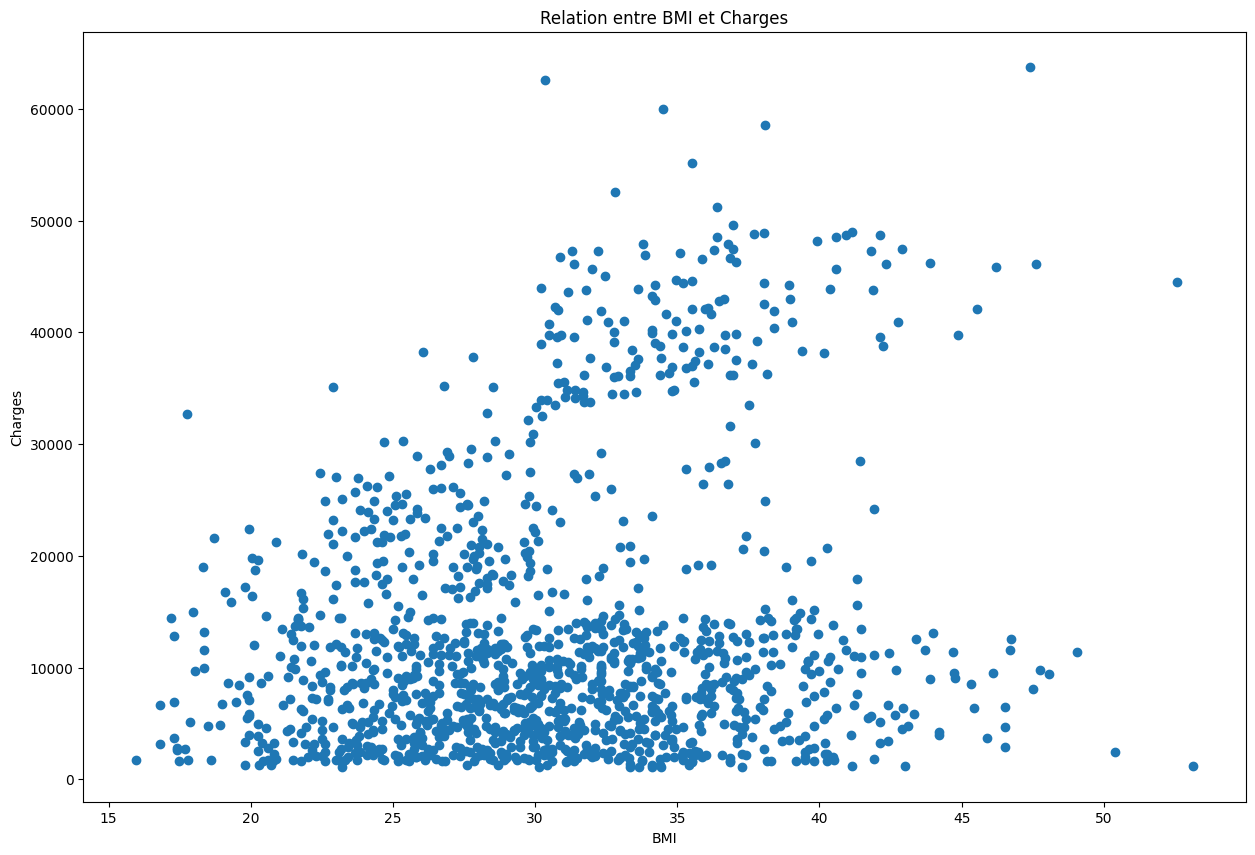

In [17]:
plt.figure(figsize=(15,10))
plt.scatter(df["bmi"], df["charges"])
plt.xlabel("BMI")
plt.ylabel("Charges")
plt.title("Relation entre BMI et Charges")
plt.show()

relation positive claire
BMI élevé → charges élevées

### B. Analyse des variables Categoriques

Nous analysons:

    • distribution de sexe    
    • distribution de children      
    • distribution de smoker 
    • distribution de region     
    • chaque variables vs charges


In [18]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


#### 1. Distribution de sexe

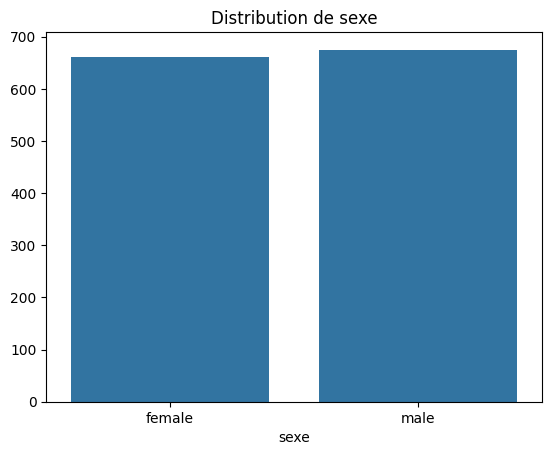

In [19]:
sns.countplot(x='sex', data=df)
plt.title("Distribution de sexe")
plt.xlabel("sexe")
plt.ylabel("")
plt.show()

#### 2. Distribution des enfants:

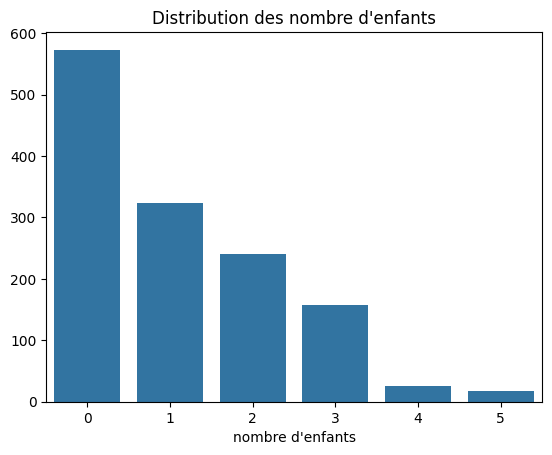

In [20]:
sns.countplot(x='children', data=df)
plt.title("Distribution des nombre d'enfants")
plt.xlabel("nombre d'enfants")
plt.ylabel("")
plt.show()

#### 3. Distribution de fumeurs

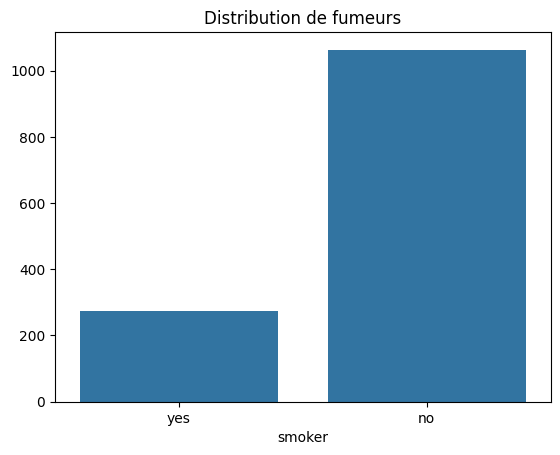

In [21]:
sns.countplot(x='smoker', data=df)
plt.title("Distribution de fumeurs")
plt.xlabel("smoker")
plt.ylabel("")
plt.show()

#### 4. Distribution des regions

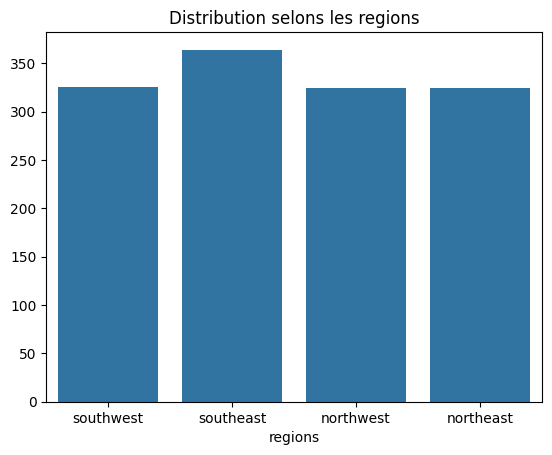

In [22]:
sns.countplot(x='region', data=df)
plt.title("Distribution selons les regions")
plt.xlabel("regions")
plt.ylabel("")
plt.show()

#### 5. charges selon sexe 
le sexe influence-t-il les charges?

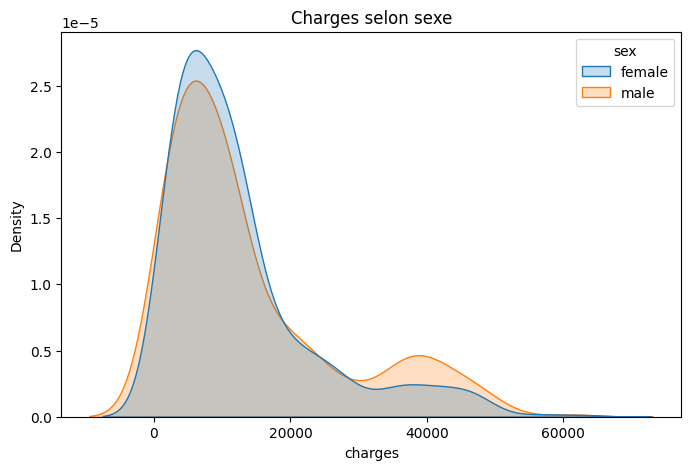

In [23]:
plt.figure(figsize=(8,5))
sns.kdeplot(data=df, x='charges', hue='sex', fill=True)
plt.title("Charges selon sexe")
plt.show()

#### 6.charges selon le nombre des enfants
le nombre des enfants influence-t-il les charges ?

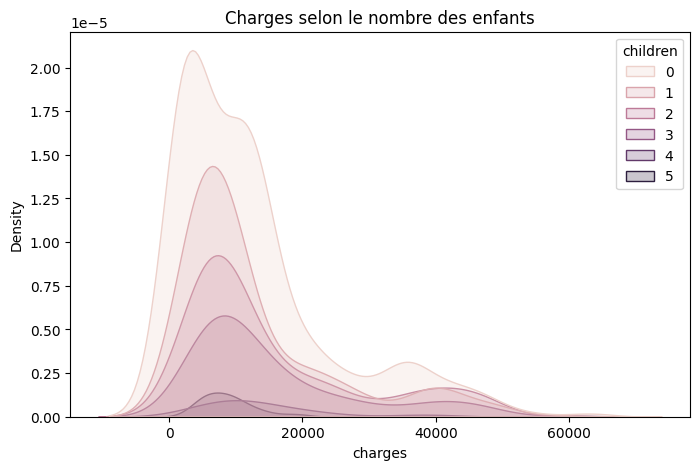

In [24]:
plt.figure(figsize=(8,5))
sns.kdeplot(data=df, x='charges', hue='children', fill=True)
plt.title("Charges selon le nombre des enfants")
plt.show()

#### 7. Charges selon fumeurs ou non
les fumeurs ayant plus des charges ?  

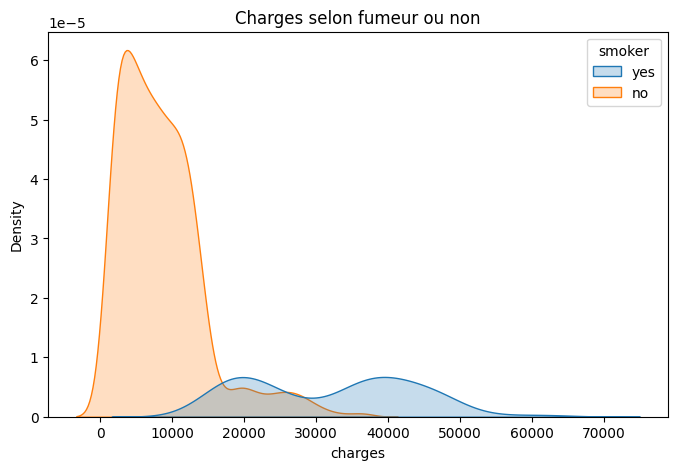

In [25]:
plt.figure(figsize=(8,5))
sns.kdeplot(data=df, x='charges', hue='smoker', fill=True)
plt.title("Charges selon fumeur ou non")
plt.show()

#### 8. charges selon les regions
la region influence les charges?

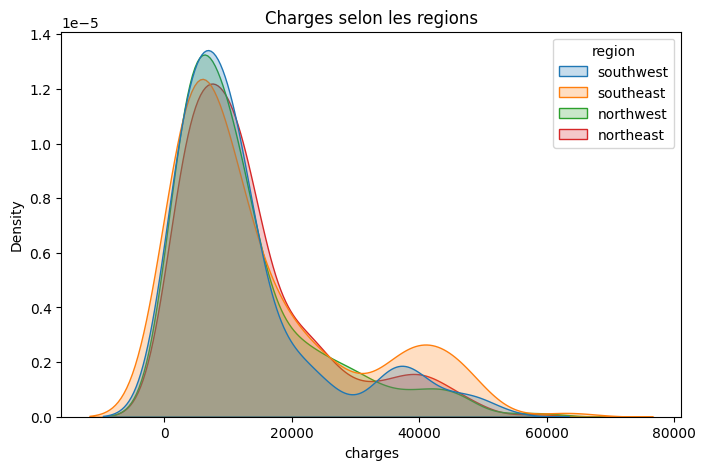

In [26]:
plt.figure(figsize=(8,5))
sns.kdeplot(data=df, x='charges', hue='region', fill=True)
plt.title("Charges selon les regions")
plt.show()

## Partie 5 : Data Preprocessing

###  Encodage des Variables Catégoriques

In [27]:
cat_col=df.select_dtypes(include='object').columns

from sklearn.preprocessing import LabelEncoder 

df_encoded = df.copy()

le=LabelEncoder()

for col in cat_col:
    df_encoded[col]=le.fit_transform(df_encoded[col])

df_encoded.head()    

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520


In [28]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

###  Mise à l'Échelle des Données

In [29]:
from sklearn.preprocessing import StandardScaler

# Scaling des variables explicatives
# (la cible "charges" reste en dollars : on ne l'encode pas)
scaler = StandardScaler()
df_encoded[['age', 'sex', 'bmi', 'children', 'smoker', 'region']] = scaler.fit_transform(df_encoded[['age', 'sex', 'bmi', 'children', 'smoker', 'region']])
df_encoded.head()

,age,sex,bmi,children,smoker,region,charges
0,-1.440418,-1.009771,-0.453160,-0.909234,1.969660,1.343163,16884.92400
1,-1.511647,0.990324,0.509422,-0.079442,-0.507702,0.438017,1725.55230
2,-0.799350,0.990324,0.383155,1.580143,-0.507702,0.438017,4449.46200
3,-0.443201,0.990324,-1.305052,-0.909234,-0.507702,-0.467128,21984.47061
4,-0.514431,0.990324,-0.292456,-0.909234,-0.507702,-0.467128,3866.85520


###  Séparation en Train et Test

In [30]:
from sklearn.model_selection import train_test_split

x = df_encoded.drop('charges',axis=1)
y = df_encoded['charges']

x_train, x_test, y_train , y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [31]:
x

,age,sex,bmi,children,smoker,region
0,-1.440418,-1.009771,-0.453160,-0.909234,1.969660,1.343163
1,-1.511647,0.990324,0.509422,-0.079442,-0.507702,0.438017
2,-0.799350,0.990324,0.383155,1.580143,-0.507702,0.438017
3,-0.443201,0.990324,-1.305052,-0.909234,-0.507702,-0.467128
4,-0.514431,0.990324,-0.292456,-0.909234,-0.507702,-0.467128
...,...,...,...,...,...,...
1333,0.767704,0.990324,0.050269,1.580143,-0.507702,-0.467128
1334,-1.511647,-1.009771,0.206053,-0.909234,-0.507702,-1.372274
1335,-1.511647,-1.009771,1.014490,-0.909234,-0.507702,0.438017
1336,-1.297958,-1.009771,-0.797524,-0.909234,-0.507702,1.343163


In [32]:
y

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1337, dtype: float64

## Partie 6 : Machine Learning

<div style="
    padding: 30px;
    border-radius: 15px;
    color: white;
    font-family: Arial, sans-serif;
">
    <h1 style="
        text-align: center;
        color: #ffffff;
        margin-bottom: 30px;
    ">
 Régression Linéaire Simple
    </h1>
</div>

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [34]:
# Initialisation et entraînement du modèle
model = LinearRegression()
model.fit(x_train, y_train)

# Prédiction sur les données de test
y_pred_lr = model.predict(x_test)


In [35]:
len(y_pred_lr)

268

In [36]:
# Calcul de l'erreur quadratique moyenne et du R²
mse = mean_squared_error(y_test, y_pred_lr)
r2 = r2_score(y_test, y_pred_lr)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Coefficient de détermination (R²): {r2:.2f}")

Mean Squared Error (MSE): 35493102.61
Coefficient de détermination (R²): 0.81


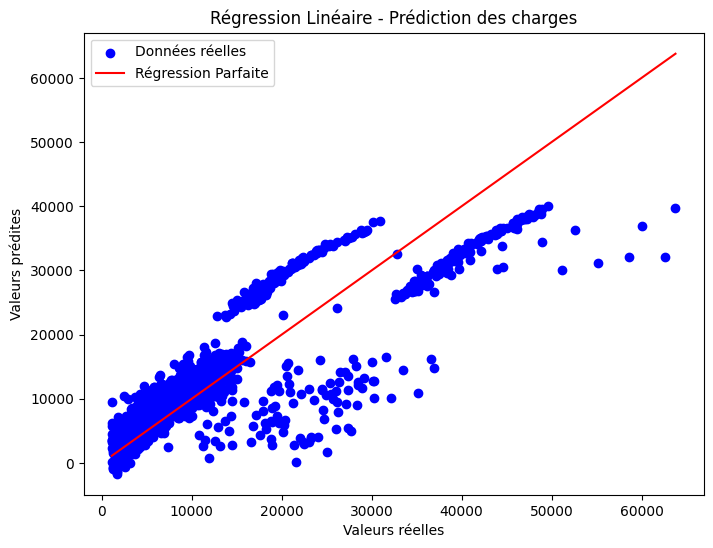

In [37]:
y_pred_lr_ = model.predict(x)

plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred_lr_, color='blue', label='Données réelles')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', label='Régression Parfaite')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Régression Linéaire - Prédiction des charges')
plt.legend()
plt.show()

• La zone 0–800 : les points suivent bien la droite rouge → le modèle prédit correctement dans cette plage

• La zone 800–1400 : les points se dispersent en deux groupes distincts → le modèle a du mal à prédire, il y a probablement une variable catégorielle importante qui crée ces deux clusters (par exemple : fumeur/non-fumeur, région, etc.)

Conclusion :
La régression linéaire capture une tendance générale mais elle est limitée ici car :
Les données ne sont pas parfaitement linéaires
Il existe probablement des interactions entre variables non capturées

Un R² en dessous de 0.80 confirmerait que la régression linéaire simple n'est pas suffisante, et qu'il faudrait envisager un modèle plus puissant 

<div style="
    padding: 30px;
    border-radius: 15px;
    color: white;
    font-family: Arial, sans-serif;
">
    <h1 style="
        text-align: center;
        color: #ffffff;
        margin-bottom: 30px;
    ">
 KNN Regresser
    </h1>
</div>

In [38]:
from sklearn.neighbors import KNeighborsRegressor

# Création et entraînement du modèle KNN Regression avec K=5
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [39]:
# Prédiction sur les données test
y_pred_knn = knn.predict(x_test)

In [40]:
# Évaluation du modèle
mse = mean_squared_error(y_test, y_pred_knn)
print(f"Erreur quadratique moyenne (MSE) : {mse:.3f}")

Erreur quadratique moyenne (MSE) : 24913721.523


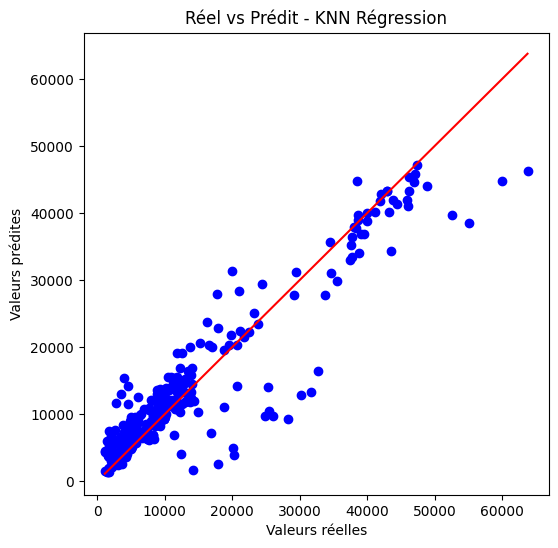

In [41]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred_knn, color='blue')

# Ligne idéale
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Réel vs Prédit - KNN Régression")

plt.show()

In [42]:
r2 = r2_score(y_test, y_pred_knn)
mae = mean_absolute_error(y_test, y_pred_knn)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_knn))

print(f"R2 Score: {r2:.4f}")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

R2 Score: 0.8644
MAE: 3108.64
RMSE: 4991.36


Le modèle KNN est globalement performant et fiable. Bien qu'il présente quelques erreurs sur les valeurs extrêmes et les outliers, il constitue une base solide pour la prédiction.

Meilleur K : 6
MSE à K=5  : 24913721.523
MSE optimal: 24589831.188


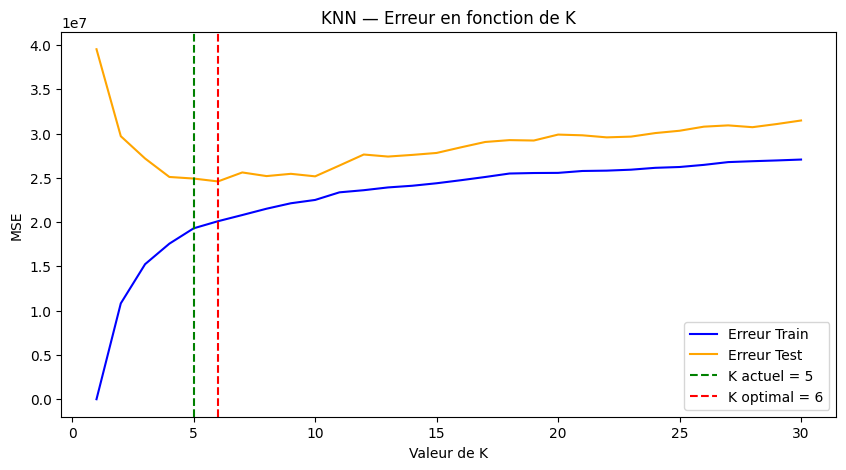

In [43]:
# Courbe erreur vs K — adapté à tes variables
train_errors = []
test_errors  = []
k_values = range(1, 31)

for k in k_values:
    knn_k = KNeighborsRegressor(n_neighbors=k)
    knn_k.fit(x_train, y_train)

    train_errors.append(mean_squared_error(y_train, knn_k.predict(x_train)))
    test_errors.append(mean_squared_error(y_test,  knn_k.predict(x_test)))

best_k = k_values[np.argmin(test_errors)]
print(f"Meilleur K : {best_k}")
print(f"MSE à K=5  : {mse:.3f}")  # ton mse existant
print(f"MSE optimal: {min(test_errors):.3f}")

plt.figure(figsize=(10, 5))
plt.plot(k_values, train_errors, color='blue',   label='Erreur Train')
plt.plot(k_values, test_errors,  color='orange', label='Erreur Test')
plt.axvline(x=5,      color='green', linestyle='--', label='K actuel = 5')
plt.axvline(x=best_k, color='red',   linestyle='--', label=f'K optimal = {best_k}')
plt.xlabel('Valeur de K')
plt.ylabel('MSE')
plt.title('KNN — Erreur en fonction de K')
plt.legend()
plt.show()


<div style="
    padding: 30px;
    border-radius: 15px;
    color: white;
    font-family: Arial, sans-serif;
">
    <h1 style="
        text-align: center;
        color: #ffffff;
        margin-bottom: 30px;
    ">
Decision Trees    </h1>
</div>

In [44]:
from sklearn.tree import DecisionTreeRegressor

tree = DecisionTreeRegressor(max_depth=3)
tree.fit(x_train, y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_le

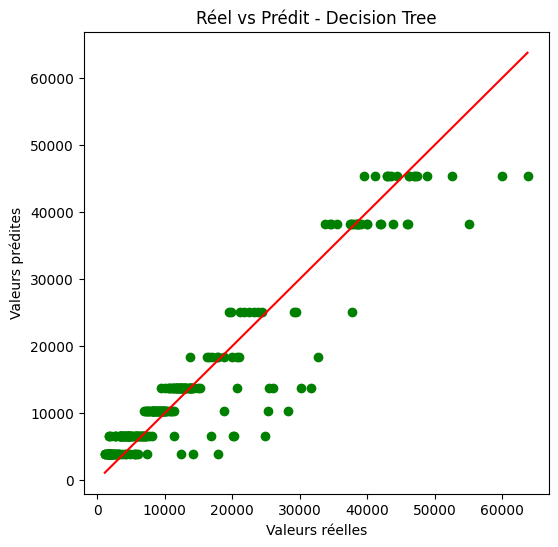

In [45]:

# Prédictions
y_pred_tree = tree.predict(x_test)

# Graphique Réel vs Prédit
plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred_tree, color='green')

# Ligne idéale
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Réel vs Prédit - Decision Tree")

plt.show()


In [46]:
r2 = r2_score(y_test, y_pred_tree)
mae = mean_absolute_error(y_test, y_pred_tree)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_tree))

print(f"R2 Score: {r2:.4f}")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

R2 Score: 0.8930
MAE: 2755.27
RMSE: 4435.20


<div style="
    padding: 30px;
    border-radius: 15px;
    color: white;
    font-family: Arial, sans-serif;
">
    <h1 style="
        text-align: center;
        color: #ffffff;
        margin-bottom: 30px;
    ">
Random Forest    </h1>
</div>

In [47]:
from sklearn.ensemble import RandomForestRegressor  
# Création et entraînement du modèle Random Forest Regressor 
rf_regressor = RandomForestRegressor(n_estimators=100, max_depth=3, random_state=42) 
rf_regressor.fit(x_train, y_train)
# Prédiction sur les données test 
y_pred_rf = rf_regressor.predict(x_test)
# Évaluation du modèle
mse = mean_squared_error(y_test, y_pred_rf) 
r2 = r2_score(y_test, y_pred_rf) 
print(f"Mean Squared Error (MSE) : {mse:.3f}") 
print(f"Coefficient de détermination (R²) : {r2:.3f}")


Mean Squared Error (MSE) : 18664595.177
Coefficient de détermination (R²) : 0.898


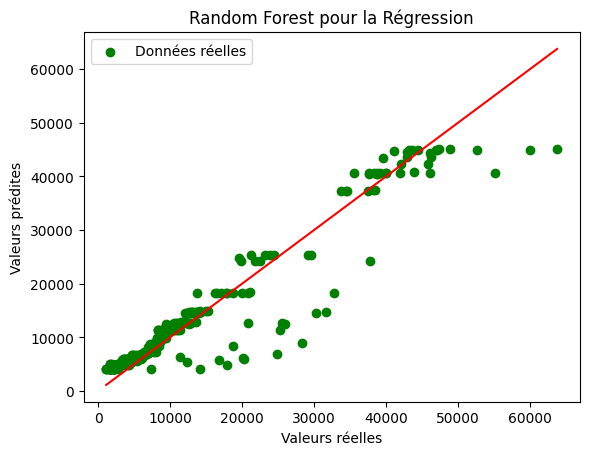

In [48]:
# Visualisation des résultats
plt.scatter(y_test, y_pred_rf, color='green', label="Données réelles")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Random Forest pour la Régression")
plt.legend()
plt.show()

In [49]:
print(f"R2 Score: {r2:.4f}")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

R2 Score: 0.8984
MAE: 2755.27
RMSE: 4435.20


<div style="
    padding: 30px;
    border-radius: 15px;
    color: white;
    font-family: Arial, sans-serif;
">
    <h1 style="
        text-align: center;
        color: #ffffff;
        margin-bottom: 30px;
    ">
SVC (Support Vector Machine) 
 </h1>
</div>

In [50]:
from sklearn.svm import SVR

In [51]:
# Création et entraînement du modèle SVR avec noyau RBF 
svr_regressor = SVR(kernel="rbf", C=1.0, epsilon=0.1) 
svr_regressor.fit(x_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [52]:
# Prédiction sur les données test 
y_pred_svr = svr_regressor.predict(x_test)

In [53]:
mse = mean_squared_error(y_test, y_pred_svr) 
r2 = r2_score(y_test, y_pred_svr)
print(f"Mean Squared Error (MSE) : {mse:.3f}") 
print(f"Coefficient de détermination (R²) : {r2:.3f}")

Mean Squared Error (MSE) : 207628992.257
Coefficient de détermination (R²) : -0.130


## Partie 7 : Model Comparison

In [54]:
print(len(y_test))
print(len(y_pred_lr))

268
268


In [55]:
models = ['Linear Regressioon','KNN','Decision Tree','Random  Forest','SVR']
mae_scores = [
    mean_absolute_error(y_test, y_pred_lr),
    mean_absolute_error(y_test, y_pred_knn),
    mean_absolute_error(y_test, y_pred_tree),
    mean_absolute_error(y_test, y_pred_rf),
    mean_absolute_error(y_test, y_pred_svr)       
]

mse_scores = [
    mean_squared_error(y_test, y_pred_lr),
    mean_squared_error(y_test, y_pred_knn),
    mean_squared_error(y_test, y_pred_tree),
    mean_squared_error(y_test, y_pred_rf),
    mean_squared_error(y_test, y_pred_svr),
]

r2_scores  = [
    r2_score(y_test, y_pred_lr),
    r2_score(y_test, y_pred_knn) ,   
    r2_score(y_test, y_pred_tree),
    r2_score(y_test, y_pred_rf),
    r2_score(y_test, y_pred_svr)                                
]
comparison_df = pd.DataFrame({
    'Model': models,
    'MAE': mae_scores,
    'MSE' : mse_scores,
    'R2' : r2_scores
})

print('\nModel Comparison')
display(comparison_df)


Model Comparison


,Model,MAE,MSE,R2
0,Linear Regressioon,4182.353155,3.549310e+07,0.806847
1,KNN,3108.637253,2.491372e+07,0.864420
2,Decision Tree,2755.269509,1.967097e+07,0.892951
3,Random Forest,2590.597410,1.866460e+07,0.898427
4,SVR,9252.905206,2.076290e+08,-0.129916


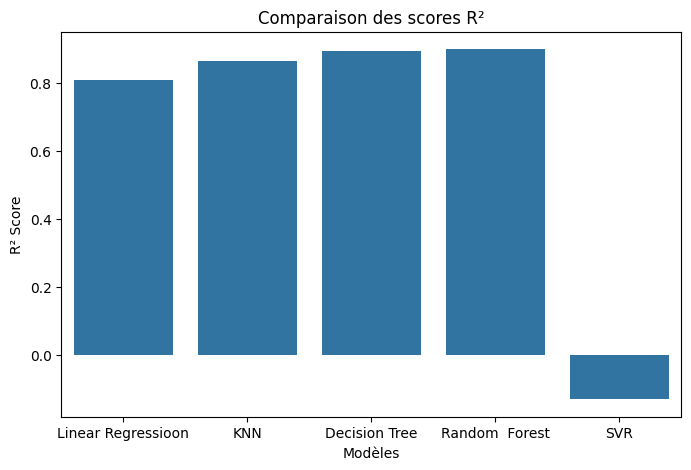

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.barplot(x='Model', y='R2', data=comparison_df)

plt.title("Comparaison des scores R²")
plt.ylabel("R² Score")
plt.xlabel("Modèles")

plt.show()

In [57]:
best_model = comparison_df.loc[comparison_df['R2'].idxmax()]
best_model

Model     Random  Forest
MAE           2590.59741
MSE      18664595.177431
R2              0.898427
Name: 3, dtype: object

## Partie 7 : predictions on new data

In [58]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [59]:
df.drop(columns='charges')

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest
...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest
1334,18,female,31.920,0,no,northeast
1335,18,female,36.850,0,no,southeast
1336,21,female,25.800,0,no,southwest


In [60]:
new_data = {
    'age': 40,
    'sex': 1,
    'bmi': 28.5,
    'children': 2,
    'smoker': 0,
    'region': 1,
}

In [61]:
new_data_df = pd.DataFrame([new_data])

In [62]:
print(scaler.feature_names_in_)

['age' 'sex' 'bmi' 'children' 'smoker' 'region']


In [63]:
new_data_scaled = scaler.transform(new_data_df)

In [64]:
prediction = model.predict(new_data_scaled)

print('la prediction des charges est : ',prediction)

la prediction des charges est :  [8543.15528191]


c:\Users\ennak\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## Partie 7 : saving the best model

In [65]:
comparison_df

,Model,MAE,MSE,R2
0,Linear Regressioon,4182.353155,3.549310e+07,0.806847
1,KNN,3108.637253,2.491372e+07,0.864420
2,Decision Tree,2755.269509,1.967097e+07,0.892951
3,Random Forest,2590.597410,1.866460e+07,0.898427
4,SVR,9252.905206,2.076290e+08,-0.129916


In [66]:
import joblib

# On sauvegarde le meilleur modèle (meilleur R²) et le scaler
modeles = {
    'Linear Regressioon': model,
    'KNN': knn,
    'Decision Tree': tree,
    'Random  Forest': rf_regressor,
    'SVR': svr_regressor,
}
best_name = comparison_df.loc[comparison_df['R2'].idxmax(), 'Model']
print('Meilleur modèle :', best_name)

joblib.dump(modeles[best_name], 'best_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

Meilleur modèle : Random  Forest


['scaler.pkl']

In [67]:
loaded_model = joblib.load('best_model.pkl')
loaded_scaler = joblib.load('scaler.pkl')

# Encodage identique au LabelEncoder (ordre alphabétique) :
# sex : female=0, male=1 | smoker : no=0, yes=1
# region : northeast=0, northwest=1, southeast=2, southwest=3
new_data = {
    'age': 40,
    'sex': 1,
    'bmi': 28.5,
    'children': 2,
    'smoker': 0,
    'region': 1,
}

new_df = pd.DataFrame([new_data])
new_df_scaled = loaded_scaler.transform(new_df)

print(f"Frais médicaux estimés : {loaded_model.predict(new_df_scaled)[0]:.2f} $")

Frais médicaux estimés : 7197.94 $


c:\Users\ennak\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


## conclusion
Le Random Forest obtient les meilleurs résultats (R² = 0,90, MAE ≈ 2 600 $). Les modèles à base d'arbres captent mieux l'effet du tabac combiné à l'IMC, qui n'est pas linéaire. Le SVR a un R² négatif : avec ses paramètres par défaut, il n'est pas adapté à une cible en dollars aussi étendue, sans réglage de C et sans mise à l'échelle de la cible.